In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

In [2]:
df = pd.read_csv('creditcard.csv')

print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
X = df.drop('Class', axis=1).values
y = df['Class'].values

scaler = StandardScaler()
X = scaler.fit_transform(X)

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

train_normal = x_train[y_train == 0]

train_normal = train_normal[:50000]

print(x_train.shape)
print(x_test.shape)

(227845, 30)
(56962, 30)


In [4]:
input_dim = x_train.shape[1]

autoencoder = Sequential([
    Input(shape=(input_dim,)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(16, activation='relu'),
    Dense(32, activation='relu'),
    Dense(input_dim, activation='linear')
])

autoencoder.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             992 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 30)                  │             990 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,334 (13.02 KB)

 Trainable params: 3,334 (13.02 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [6]:
history = autoencoder.fit(
    train_normal,
    train_normal,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_split=0.2
)

Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - loss: 0.9372 - mae: 0.6472 - val_loss: 0.8795 - val_mae: 0.6392
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.8298 - mae: 0.6148 - val_loss: 0.7855 - val_mae: 0.6002
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.7422 - mae: 0.5799 - val_loss: 0.7181 - val_mae: 0.5714
Epoch 4/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.6819 - mae: 0.5555 - val_loss: 0.6725 - val_mae: 0.5496
Epoch 5/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.6285 - mae: 0.5343 - val_loss: 0.6226 - val_mae: 0.5279
Epoch 6/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5795 - mae: 0.5126 - val_loss: 0.6003 - val_mae: 0.5191
Epoch 7/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5536 - mae: 0.5030 - val_loss: 0.5583 - val_mae: 0.5010
Epoch 8/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.5247 - mae: 0.4908 - val_loss: 0.5411 - val_mae: 0.4945
Epoch 9/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - l

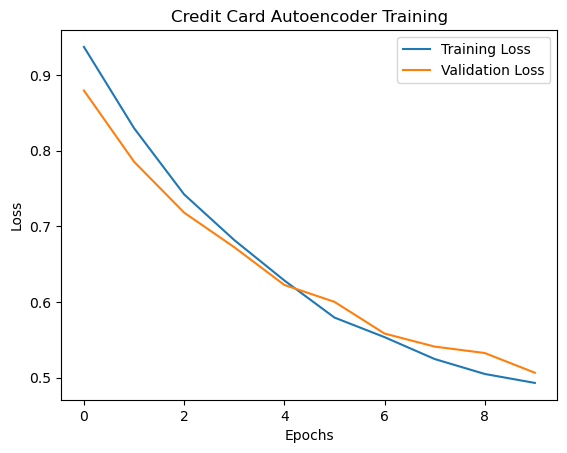

In [7]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Credit Card Autoencoder Training')
plt.legend()
plt.show()

In [8]:
reconstructions = autoencoder.predict(x_test)

mse = np.mean(np.square(x_test - reconstructions), axis=1)

print(mse[:10])

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step
[0.2472904  0.96412437 3.59568055 0.12326228 0.27973121 0.1176803
 0.29709264 0.18278066 0.15826929 0.3114295 ]


In [9]:
train_predictions = autoencoder.predict(train_normal)

train_mse = np.mean(
    np.square(train_normal - train_predictions), axis=1
)

threshold = np.percentile(train_mse, 95)

print("Threshold:", threshold)

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
Threshold: 1.118867453859272


In [10]:
predictions = mse > threshold

print("Total Transactions:", len(x_test))
print("Fraudulent Transactions Detected:", np.sum(predictions))
print("Normal Transactions:", np.sum(~predictions))

Total Transactions: 56962
Fraudulent Transactions Detected: 3085
Normal Transactions: 53877


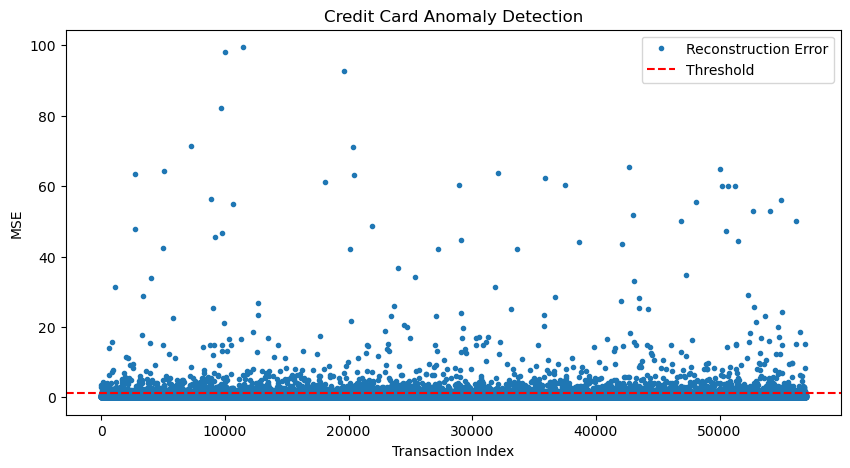

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(mse, '.', label='Reconstruction Error')
plt.axhline(threshold, color='red', linestyle='--', label='Threshold')

plt.xlabel('Transaction Index')
plt.ylabel('MSE')
plt.title('Credit Card Anomaly Detection')
plt.legend()
plt.show()